### Plotting alpha mass fraction against baryon density for symmetric nuclear matter over a range of T

In [1]:
# Imports

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq


In [2]:
# Define constants

T_1 = 2.0 # Temp [MeV]
T_2 = 4.0 
T_3 = 8.0
m_p = 938.272 # mass of proton [MeV/c^2]
lamda_1 = 197.326 * (2 * np.pi/(m_p * T_1))**(1/2) # nucleon thermal wavelength [fm^-1] assuming m_p=m_n
lamda_2 = 197.326 * (2 * np.pi/(m_p * T_2))**(1/2) 
lamda_3 = 197.326 * (2 * np.pi/(m_p * T_3))**(1/2) 
lamda_alpha_1 = lamda_1 / 2 # alpha particle thermal wavelength [fm^-1]
lamda_alpha_2 = lamda_2 / 2 
lamda_alpha_3 = lamda_3 / 2 
E_alpha = 28.3 # alpha particle binding energy [MeV]
Y_p = 0.5 # proton fraction


# virial coefficients for T = 2 MeV
b_n_1 = 0.303
b_pn_1 = 6.10
b_nuc_1 = 6.40
b_alpha_n_1 = 2.26
b_alpha_1 = 4.12

# virial coefficients for T = 4 MeV
b_n_2 = 0.307
b_pn_2 = 3.19
b_nuc_2 = 3.50
b_alpha_n_2 = 2.73
b_alpha_2 = 7.44

# virial coefficients for T = 8 MeV
b_n_3 = 0.309
b_pn_3 = 2.11
b_nuc_3 = 2.42
b_alpha_n_3 = 2.92
b_alpha_3 = 16.5

In [4]:
# Calculate fugacities

#---------------------
# T = 2 MeV
#---------------------

z_n_1 = np.linspace(1e-8, 0.03, 100) # range of neutron fugacities starting at small positive value

# solve quartic for z_p

z_p_1 = []

for zn in z_n_1:
    a = ((32 * Y_p - 16)/(1 - Y_p)) * b_alpha_1 * zn**4 * np.exp(2 * E_alpha/T_1)
    b = (32 * Y_p - 16)/(1 - Y_p) * b_alpha_n_1 * zn**2 * np.exp(E_alpha/T_1) - 8 * b_alpha_n_1 * zn**2 * np.exp(E_alpha/T_1)
    c = ((8 * Y_p)/(1 - Y_p)) * b_alpha_n_1 * zn**3 * np.exp(E_alpha/T_1) + ((16 * Y_p - 8)/(1 - Y_p)) * (zn**2 * np.exp(E_alpha/T_1) + 2 * zn**3 * np.exp(E_alpha/T_1) * b_alpha_n_1) - 2 * b_n_1
    d = ((2 * Y_p)/(1 - Y_p)) * zn * b_pn_1 - 1 - 2 * (zn * b_pn_1)
    e = (Y_p/(1 - Y_p)) * (zn + 2 * zn**2 * b_n_1)

    def g(z_p):
        return a * z_p**4 + b * z_p**3 + c * z_p**2 + d * z_p + e

    z_p = brentq(g, 0.0, 0.03)
    z_p_1.append(z_p)
z_p_1 = np.array(z_p_1)


z_alpha_1 = z_n_1**2 * z_p_1**2 * np.exp(E_alpha/T_1) # alpha particle fugacity

valid_1 = ((z_n_1 < 0.03) & (z_p_1 < 0.03) & (z_alpha_1 < 0.27))

#-------------------------
# T = 4 MeV
#-------------------------

z_n_2 = np.linspace(1e-8, 0.10, 100) # range of neutron fugacities starting at small positive value

# solve quartic for z_p

z_p_2 = []

for zn in z_n_2:
    a = ((32 * Y_p - 16)/(1 - Y_p)) * b_alpha_2 * zn**4 * np.exp(2 * E_alpha/T_2)
    b = (32 * Y_p - 16)/(1 - Y_p) * b_alpha_n_2 * zn**2 * np.exp(E_alpha/T_2) - 8 * b_alpha_n_2 * zn**2 * np.exp(E_alpha/T_2)
    c = ((8 * Y_p)/(1 - Y_p)) * b_alpha_n_2 * zn**3 * np.exp(E_alpha/T_2) + ((16 * Y_p - 8)/(1 - Y_p)) * (zn**2 * np.exp(E_alpha/T_2) + 2 * zn**3 * np.exp(E_alpha/T_2) * b_alpha_n_2) - 2 * b_n_2
    d = ((2 * Y_p)/(1 - Y_p)) * zn * b_pn_2 - 1 - 2 * (zn * b_pn_2)
    e = (Y_p/(1 - Y_p)) * (zn + 2 * zn**2 * b_n_2)

    def g(z_p):
        return a * z_p**4 + b * z_p**3 + c * z_p**2 + d * z_p + e

    z_p = brentq(g, 0.0, 0.10)
    z_p_2.append(z_p)
z_p_2 = np.array(z_p_2)


z_alpha_2 = z_n_2**2 * z_p_2**2 * np.exp(E_alpha/T_2) # alpha particle fugacity

valid_2 = ((z_n_2 < 0.10) & (z_p_2 < 0.10) & (z_alpha_2 < 0.09))

#-------------------------
# T = 8 MeV
#-------------------------

z_n_3 = np.linspace(1e-8, 0.16, 100) # range of neutron fugacities starting at small positive value

# solve quartic for z_p

z_p_3 = []

for zn in z_n_3:
    a = ((32 * Y_p - 16)/(1 - Y_p)) * b_alpha_3 * zn**4 * np.exp(2 * E_alpha/T_3)
    b = (32 * Y_p - 16)/(1 - Y_p) * b_alpha_n_3 * zn**2 * np.exp(E_alpha/T_3) - 8 * b_alpha_n_3 * zn**2 * np.exp(E_alpha/T_3)
    c = ((8 * Y_p)/(1 - Y_p)) * b_alpha_n_3 * zn**3 * np.exp(E_alpha/T_3) + ((16 * Y_p - 8)/(1 - Y_p)) * (zn**2 * np.exp(E_alpha/T_3) + 2 * zn**3 * np.exp(E_alpha/T_3) * b_alpha_n_3) - 2 * b_n_3
    d = ((2 * Y_p)/(1 - Y_p)) * zn * b_pn_3 - 1 - 2 * (zn * b_pn_3)
    e = (Y_p/(1 - Y_p)) * (zn + 2 * zn**2 * b_n_3)

    def g(z_p):
        return a * z_p**4 + b * z_p**3 + c * z_p**2 + d * z_p + e

    z_p = brentq(g, 0.0, 0.16)
    z_p_3.append(z_p)
z_p_3 = np.array(z_p_3)


z_alpha_3 = z_n_3**2 * z_p_3**2 * np.exp(E_alpha/T_3) # alpha particle fugacity

valid_3 = ((z_n_3 < 0.16) & (z_p_3 < 0.16) & (z_alpha_3 < 0.03))


In [5]:
# Calculate number densities including all interactions

#------------------------------
# T = 2 MeV
#------------------------------
n_n_1 = (2/lamda_1**3) * (z_n_1 + 2 * z_n_1**2 * b_n_1 + 2 * z_n_1 * z_p_1 * b_pn_1 + 8 * z_n_1 * z_alpha_1 * b_alpha_n_1) # neutron number density
n_p_1 = (2/lamda_1**3) * (z_p_1 + 2 * z_p_1**2 * b_n_1 + 2 * z_n_1 * z_p_1 * b_pn_1 + 8 * z_p_1 * z_alpha_1 * b_alpha_n_1) # proton number density
n_alpha_1 = (1/lamda_alpha_1**3) * (z_alpha_1 + 2 * z_alpha_1 * (z_n_1 + z_p_1) * b_alpha_n_1 + 2 * z_alpha_1**2 * b_alpha_1) # alpha particle number density
n_b_1 = (n_n_1 + n_p_1 + 4 * n_alpha_1) # baryon number density [fm^-3]

#------------------------------
# T = 4 MeV
#------------------------------
n_n_2 = (2/lamda_2**3) * (z_n_2 + 2 * z_n_2**2 * b_n_2 + 2 * z_n_2 * z_p_2 * b_pn_2 + 8 * z_n_2 * z_alpha_2 * b_alpha_n_2)
n_p_2 = (2/lamda_2**3) * (z_p_2 + 2 * z_p_2**2 * b_n_2 + 2 * z_n_2 * z_p_2 * b_pn_2 + 8 * z_p_2 * z_alpha_2 * b_alpha_n_2) 
n_alpha_2 = (1/lamda_alpha_2**3) * (z_alpha_2 + 2 * z_alpha_2 * (z_n_2 + z_p_2) * b_alpha_n_2 + 2 * z_alpha_2**2 * b_alpha_2)
n_b_2 = (n_n_2 + n_p_2 + 4 * n_alpha_2) 


#-----------------------------
# T = 8 MeV
#-----------------------------
n_n_3 = (2/lamda_3**3) * (z_n_3 + 2 * z_n_3**2 * b_n_3 + 2 * z_n_3 * z_p_3 * b_pn_3 + 8 * z_n_3 * z_alpha_3 * b_alpha_n_3) 
n_p_3 = (2/lamda_3**3) * (z_p_3 + 2 * z_p_3**2 * b_n_3 + 2 * z_n_3 * z_p_3 * b_pn_3 + 8 * z_p_3 * z_alpha_3 * b_alpha_n_3) 
n_alpha_3 = (1/lamda_alpha_3**3) * (z_alpha_3 + 2 * z_alpha_3 * (z_n_3 + z_p_3) * b_alpha_n_3 + 2 * z_alpha_3**2 * b_alpha_3) 
n_b_3 = (n_n_3 + n_p_3 + 4 * n_alpha_3)


In [6]:
# Calculate alpha mass fractions


x_alpha_1 = 4 * n_alpha_1 / n_b_1 # alpha mass fraction
x_alpha_2 = 4 * n_alpha_2 / n_b_2 
x_alpha_3 = 4 * n_alpha_3 / n_b_3 

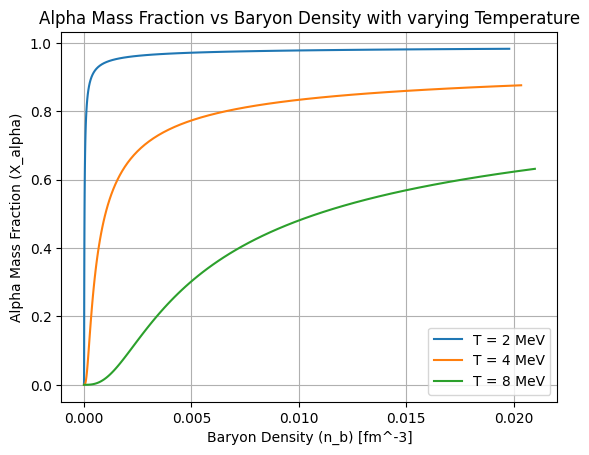

In [7]:
# Plot results

plt.plot(n_b_1[valid_1], x_alpha_1[valid_1], label='T = 2 MeV')
plt.plot(n_b_2[valid_2], x_alpha_2[valid_2], label='T = 4 MeV')
plt.plot(n_b_3[valid_3], x_alpha_3[valid_3], label='T = 8 MeV')
plt.xlabel('Baryon Density (n_b) [fm^-3]')
plt.ylabel('Alpha Mass Fraction (X_alpha)')
plt.title(f'Alpha Mass Fraction vs Baryon Density with varying Temperature')
plt.grid()
plt.legend()
plt.show()